# Oxygen Calibration Clean / Combine

- match profiles

In [19]:
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

import numpy as np
import pandas as pd

In [20]:
excel_file = '/Users/bell/Downloads/WCOA26_O2_compiled.xlsx'

In [21]:
#load oxygen winkler data
oxydf = pd.read_excel(excel_file, sheet_name='Data',skiprows=4)

oxydf = oxydf.dropna(subset='Date anal.')
oxydf = oxydf.dropna(axis=1,how='all')

oxydf['O2 um/L'] = oxydf['O2 (mg/L)'] * 31.252

In [22]:
#load bottle files from upcasts
btldf = pd.read_excel(excel_file, sheet_name='SKQFociBTLReport')

btldf['castno'] = btldf['cast'].str[9:].str[:3].apply(pd.to_numeric, errors='coerce')

In [23]:
#merge on matching cast number and bottle number
df_merged = pd.merge(btldf,oxydf,left_on=['castno','bottle'],right_on=['Cast #','Niskin#'])

In [24]:
df_merged['O2, uM/kg00'] = df_merged['O2 um/L']/((1000+df_merged['sigma-t00'])/1000)
df_merged['O2, uM/kg11'] = df_merged['O2 um/L']/((1000+df_merged['sigma-t11'])/1000)

In [25]:
df_merged['O2, uM/kg00, diff'] = df_merged['sbox0mm/kg']-df_merged['O2, uM/kg00']
df_merged['O2, uM/kg11, diff'] = df_merged['sbox1mm/kg']-df_merged['O2, uM/kg11']
df_merged['O2, uM/kg00, diff_QC'] = 0
df_merged['O2, uM/kg11, diff_QC'] = 0

df_merged['O2, uM/kg00, ratio'] = df_merged['O2, uM/kg00']/df_merged['sbox0mm/kg']
df_merged['O2, uM/kg11, ratio'] = df_merged['O2, uM/kg11']/df_merged['sbox1mm/kg']
df_merged['O2, uM/kg00, ratio_QC'] = 0
df_merged['O2, uM/kg11, ratio_QC'] = 0

In [26]:
df_merged = df_merged.set_index(df_merged.datetime)
df_merged = df_merged.drop(columns='datetime')

df_merged = df_merged[df_merged['O2, uM/kg00'] != np.nan]

In [27]:
df_merged.to_csv(excel_file.replace('.xlsx','.merged_140.csv'))

## Field Calibration Methods

### sources of errors
- Winkler accuracy (sampling and processing)
- CTD oxygen/pressure offset : sensor lag due to being downstream in a pumped flow (5s lag in Sikuliaq case... could refine better?)
- hysteresis / T/S/P offsets
- slope correction non-linearity at low values of oxy conc

### Bulk slope offset

Seabird suggests not to evaluate the offset but to evaluate the slope as the drift is in the slope.  See below for Seabird Method.
FOCI has historically calculated the bulk offset correction (while not forcing through zero... which we probably should).  The bulk method treats low and high concentrations equally, but this is not necessarily the case and SBE suggests not doing an offset for values less than **???** 


Text(0.5, 0, 'Temperature')

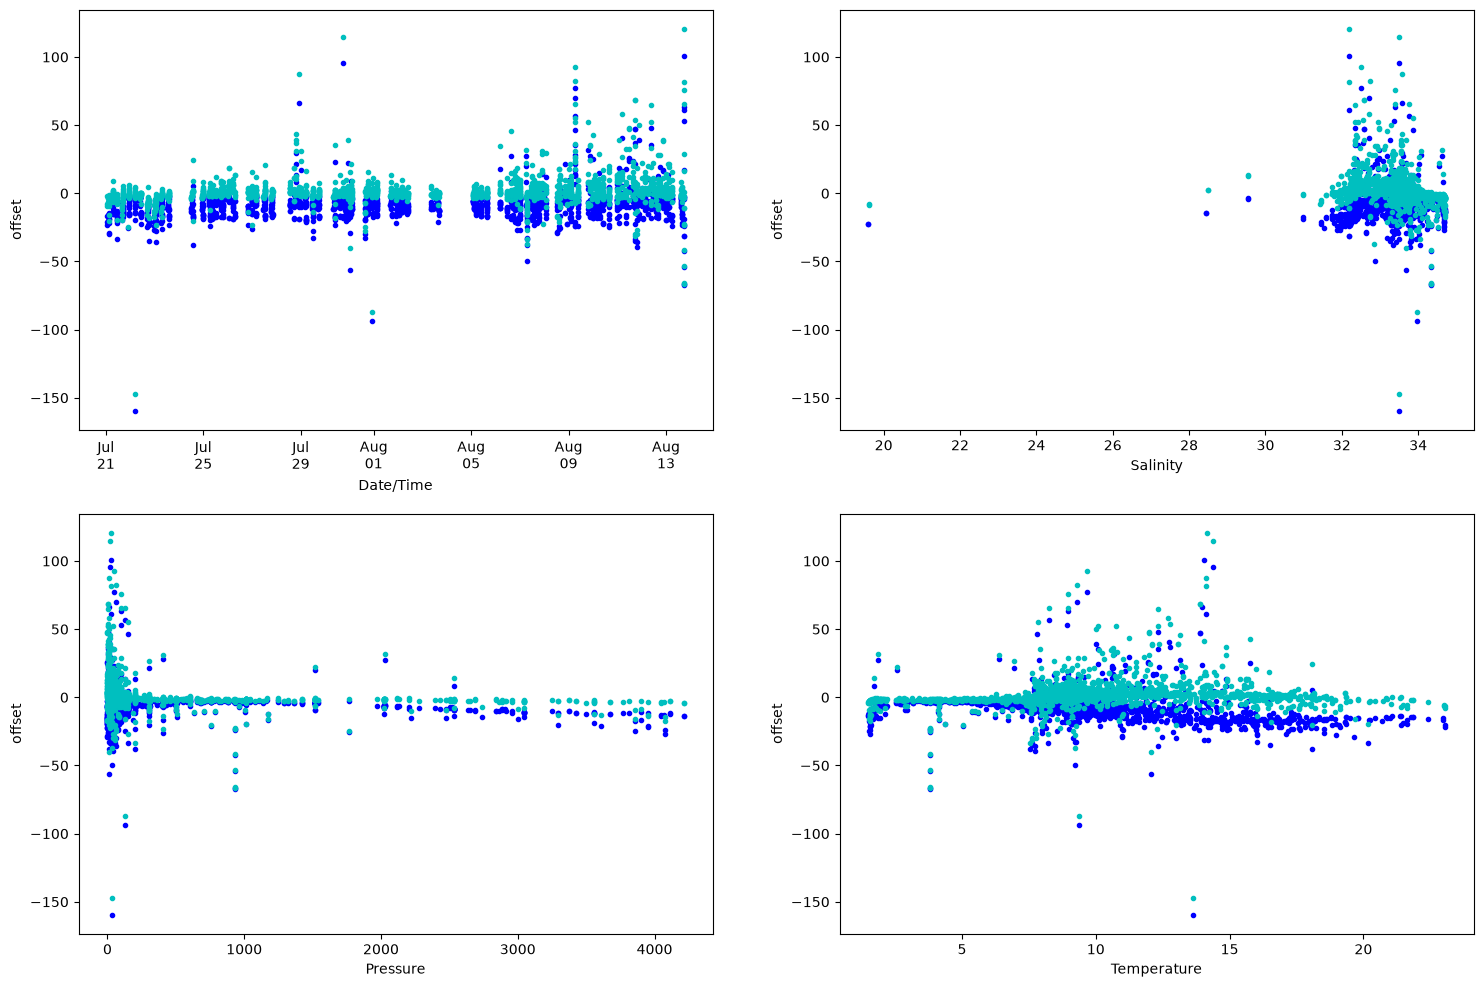

In [28]:
#Plot Basic Offset for Evaluation
fig, ax = plt.subplots(2,2,figsize=(18, 12))
plt.subplot(221)
plt.plot(df_merged.index,df_merged['O2, uM/kg00, diff'],'b.')
plt.plot(df_merged.index,df_merged['O2, uM/kg11, diff'],'c.')
ax = plt.gca()
xfmt = mdates.DateFormatter('%b\n%d')
ax.xaxis.set_major_formatter(xfmt)
plt.ylabel('offset')
plt.xlabel('Date/Time')

plt.subplot(222)
plt.plot(df_merged['sal00'],df_merged['O2, uM/kg00, diff'],'b.')
plt.plot(df_merged['sal11'],df_merged['O2, uM/kg11, diff'],'c.')
plt.ylabel('offset')
plt.xlabel('Salinity')

plt.subplot(223)
plt.plot(df_merged['prdm'],df_merged['O2, uM/kg00, diff'],'b.')
plt.plot(df_merged['prdm'],df_merged['O2, uM/kg11, diff'],'c.')
plt.ylabel('offset')
plt.xlabel('Pressure')

plt.subplot(224)
plt.plot(df_merged['t090c'],df_merged['O2, uM/kg00, diff'],'b.')
plt.plot(df_merged['t190c'],df_merged['O2, uM/kg11, diff'],'c.')
plt.ylabel('offset')
plt.xlabel('Temperature')


Text(0.5, 0, 'Temperature')

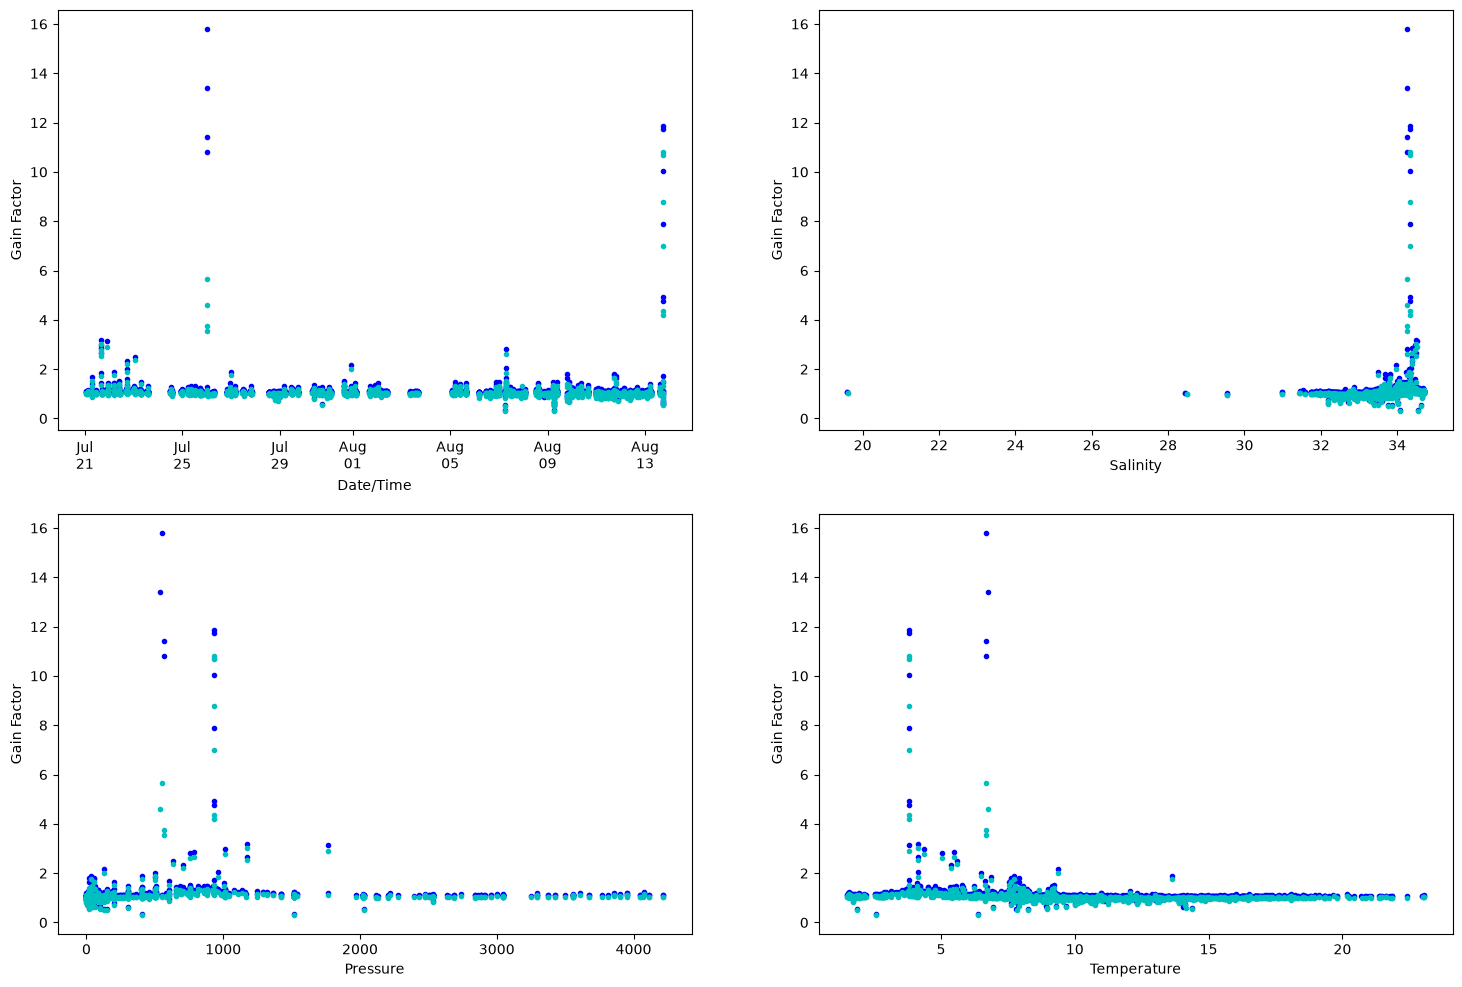

In [29]:
#Plot Basic Ration for Evaluation
fig, ax = plt.subplots(2,2,figsize=(18, 12))
plt.subplot(221)
plt.plot(df_merged.index,df_merged['O2, uM/kg00, ratio'],'b.')
plt.plot(df_merged.index,df_merged['O2, uM/kg11, ratio'],'c.')
ax = plt.gca()
xfmt = mdates.DateFormatter('%b\n%d')
ax.xaxis.set_major_formatter(xfmt)
plt.ylabel('Gain Factor')
plt.xlabel('Date/Time')

plt.subplot(222)
plt.plot(df_merged['sal00'],df_merged['O2, uM/kg00, ratio'],'b.')
plt.plot(df_merged['sal11'],df_merged['O2, uM/kg11, ratio'],'c.')
plt.ylabel('Gain Factor')
plt.xlabel('Salinity')

plt.subplot(223)
plt.plot(df_merged['prdm'],df_merged['O2, uM/kg00, ratio'],'b.')
plt.plot(df_merged['prdm'],df_merged['O2, uM/kg11, ratio'],'c.')
plt.ylabel('Gain Factor')
plt.xlabel('Pressure')

plt.subplot(224)
plt.plot(df_merged['t090c'],df_merged['O2, uM/kg00, ratio'],'b.')
plt.plot(df_merged['t190c'],df_merged['O2, uM/kg11, ratio'],'c.')
plt.ylabel('Gain Factor')
plt.xlabel('Temperature')


In [30]:
# Property Property

Text(0.5, 0, 'SBE CTD Oxygens uM/kg')

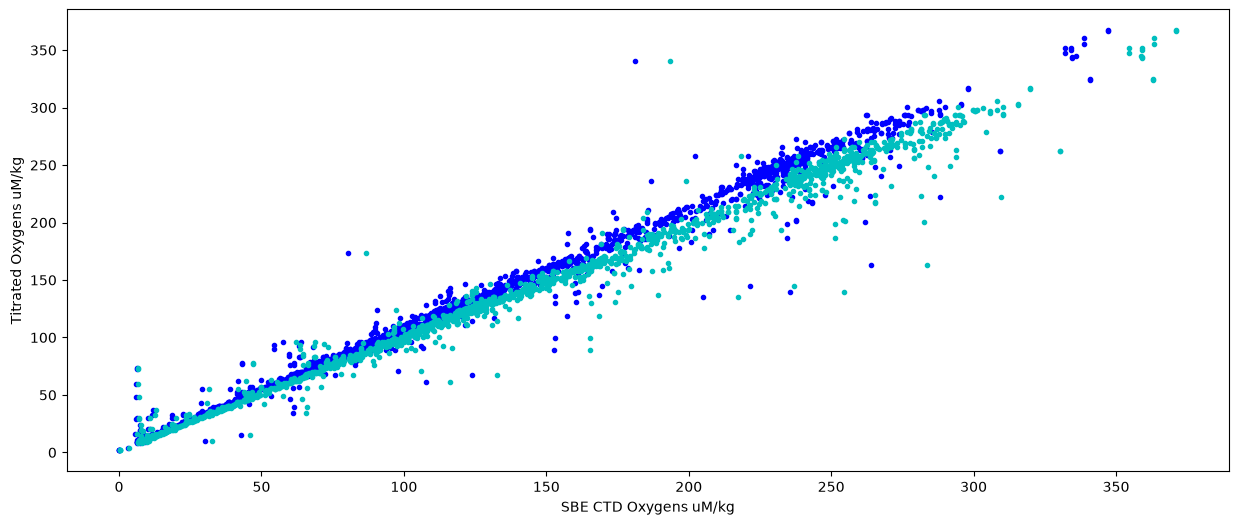

In [31]:
fig, ax = plt.subplots(figsize=(15, 6))
plt.plot(df_merged['sbox0mm/kg'],df_merged['O2, uM/kg00'],'b.')
plt.plot(df_merged['sbox1mm/kg'],df_merged['O2, uM/kg11'],'c.')
plt.ylabel('Titrated Oxygens uM/kg')
plt.xlabel('SBE CTD Oxygens uM/kg')

Text(0.5, 0, 'SBE CTD Oxygens uM/kg')

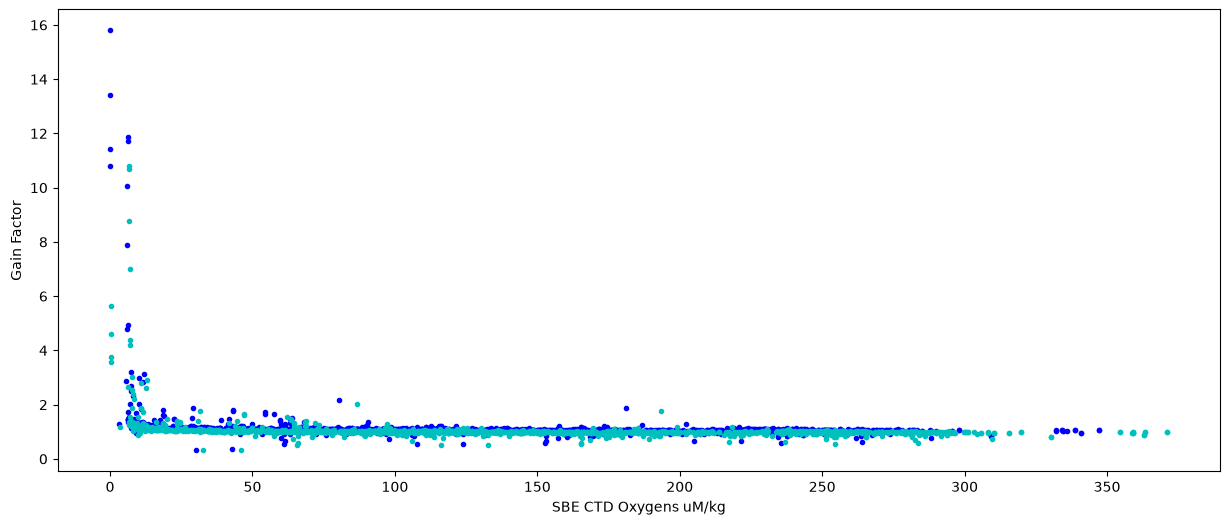

In [32]:
fig, ax = plt.subplots(figsize=(15, 6))
plt.plot(df_merged['sbox0mm/kg'],df_merged['O2, uM/kg00, ratio'],'b.')
plt.plot(df_merged['sbox1mm/kg'],df_merged['O2, uM/kg11, ratio'],'c.')
plt.ylabel('Gain Factor')
plt.xlabel('SBE CTD Oxygens uM/kg')

Text(0.5, 0, 'Date/Time')

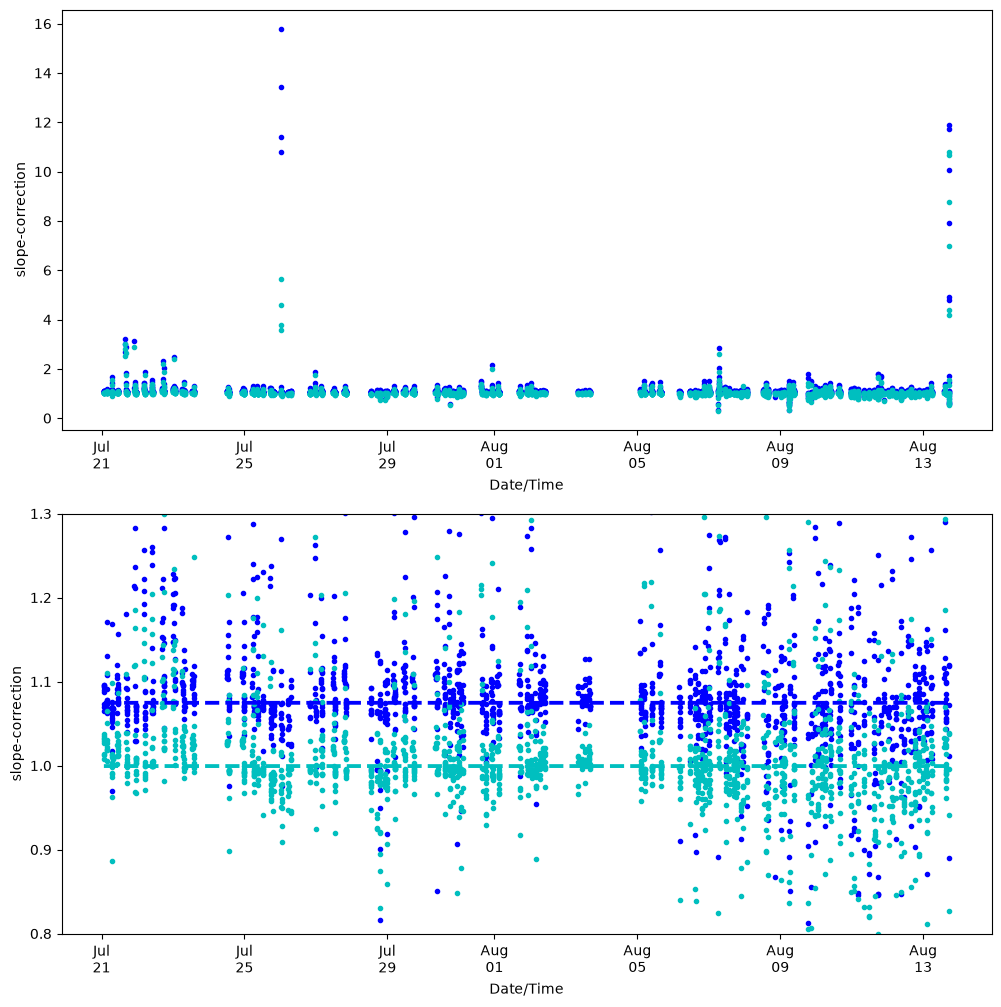

In [33]:
#Plot Basic Ratio for Evaluation
fig, ax = plt.subplots(2,1,figsize=(12, 12))
plt.subplot(211)
plt.plot(df_merged.index,(df_merged['O2, uM/kg00']/df_merged['sbox0mm/kg']),'b.')
plt.plot(df_merged.index,(df_merged['O2, uM/kg11']/df_merged['sbox1mm/kg']),'c.')
ax = plt.gca()
xfmt = mdates.DateFormatter('%b\n%d')
ax.xaxis.set_major_formatter(xfmt)
plt.ylabel('slope-correction')
plt.xlabel('Date/Time')

plt.subplot(212)
plt.plot(df_merged.index,(df_merged['O2, uM/kg00']/df_merged['sbox0mm/kg']),'b.')
plt.plot(df_merged.index,(df_merged['O2, uM/kg11']/df_merged['sbox1mm/kg']),'c.')
plt.plot(df_merged.index,np.ones(len(df_merged))*(df_merged['O2, uM/kg00']/df_merged['sbox0mm/kg']).median(),'b--',linewidth=2.75)
plt.plot(df_merged.index,np.ones(len(df_merged))*(df_merged['O2, uM/kg11']/df_merged['sbox1mm/kg']).median(),'c--',linewidth=2.75)
ax = plt.gca()
ax.set_ylim([.8,1.3])
xfmt = mdates.DateFormatter('%b\n%d')
ax.xaxis.set_major_formatter(xfmt)
plt.ylabel('slope-correction')
plt.xlabel('Date/Time')


In [34]:
print('Primary Corr Ratio:   median:{0:.3f} mean:{1:.3f} '.format((df_merged['O2, uM/kg00']/df_merged['sbox0mm/kg']).median(), (df_merged['O2, uM/kg00']/df_merged['sbox0mm/kg']).mean()))
print('Secondary Corr Ratio: median:{0:.3f} mean:{1:.3f} '.format((df_merged['O2, uM/kg11']/df_merged['sbox1mm/kg']).median(), (df_merged['O2, uM/kg11']/df_merged['sbox1mm/kg']).mean()))

Primary Corr Ratio:   median:1.075 mean:1.152 
Secondary Corr Ratio: median:0.999 mean:1.051 


Text(0.5, 0, 'Temperature')

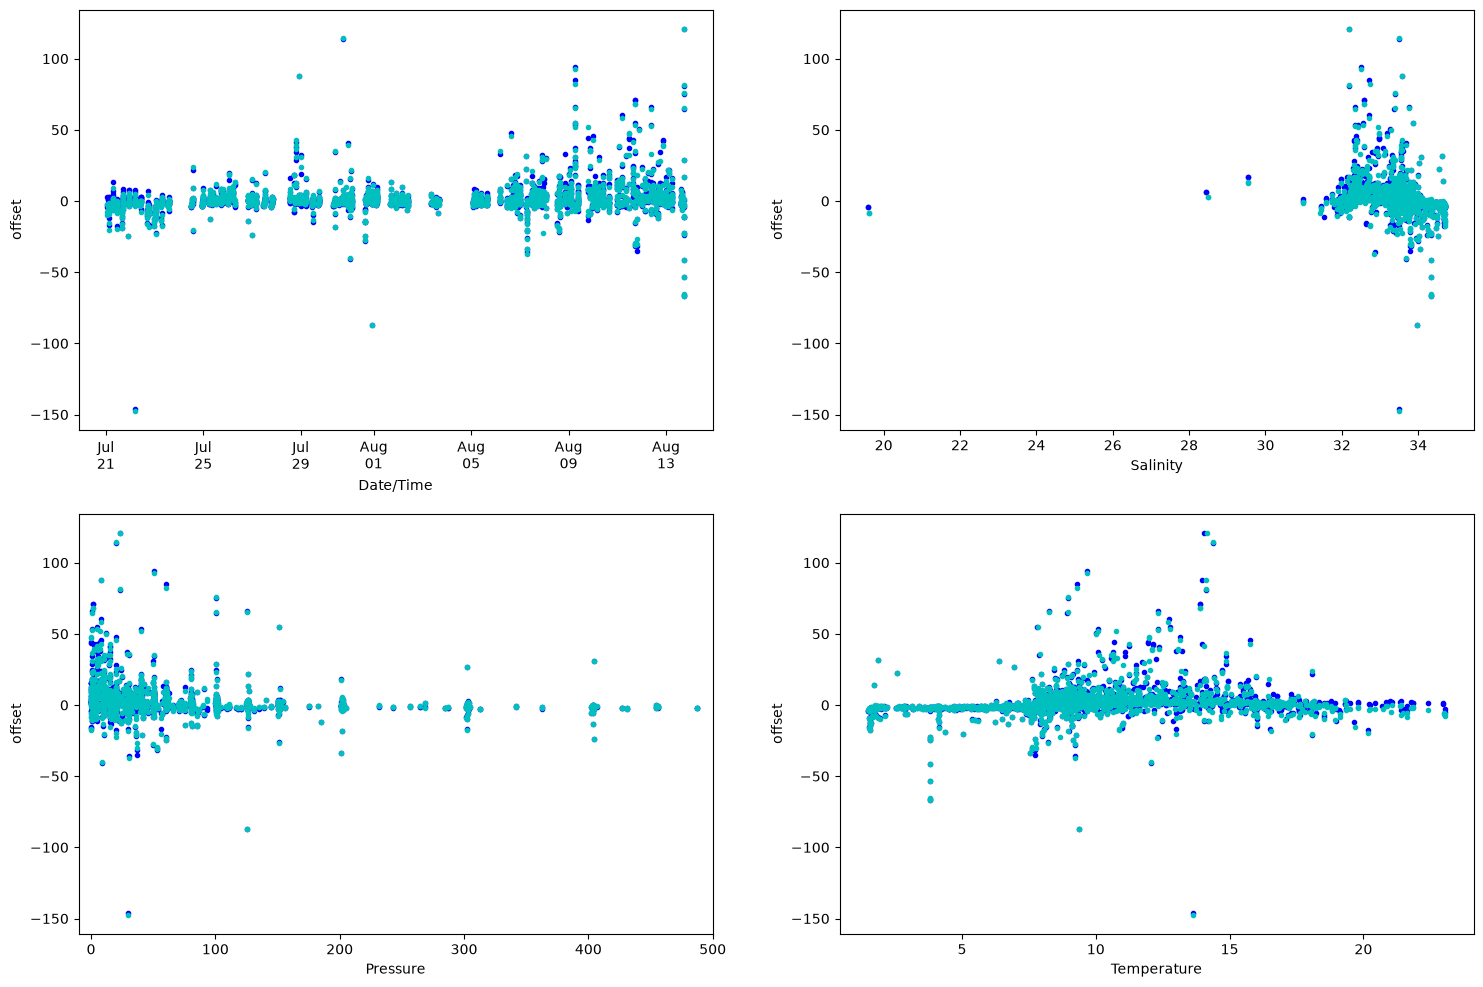

In [35]:
ratio_cor1 = 1.076
ratio_cor2 = 1.000

#Plot Offset Corrected Difference for Evaluation
fig, ax = plt.subplots(2,2,figsize=(18, 12))
plt.subplot(221)
plt.plot(df_merged.index,(df_merged['sbox0mm/kg']*ratio_cor1-df_merged['O2, uM/kg00']),'b.')
plt.plot(df_merged.index,(df_merged['sbox1mm/kg']*ratio_cor2-df_merged['O2, uM/kg11']),'c.')
ax = plt.gca()
xfmt = mdates.DateFormatter('%b\n%d')
ax.xaxis.set_major_formatter(xfmt)
plt.ylabel('offset')
plt.xlabel('Date/Time')

plt.subplot(222)
plt.plot(df_merged['sal00'],(df_merged['sbox0mm/kg']*ratio_cor1-df_merged['O2, uM/kg00']),'b.')
plt.plot(df_merged['sal11'],(df_merged['sbox1mm/kg']*ratio_cor2-df_merged['O2, uM/kg11']),'c.')
plt.ylabel('offset')
plt.xlabel('Salinity')

plt.subplot(223)
plt.plot(df_merged['prdm'],(df_merged['sbox0mm/kg']*ratio_cor1-df_merged['O2, uM/kg00']),'b.')
plt.plot(df_merged['prdm'],(df_merged['sbox1mm/kg']*ratio_cor2-df_merged['O2, uM/kg11']),'c.')
plt.ylabel('offset')
plt.xlabel('Pressure')
plt.xlim([-10,500])

plt.subplot(224)
plt.plot(df_merged['t090c'],(df_merged['sbox0mm/kg']*ratio_cor1-df_merged['O2, uM/kg00']),'b.')
plt.plot(df_merged['t190c'],(df_merged['sbox1mm/kg']*ratio_cor2-df_merged['O2, uM/kg11']),'c.')
plt.ylabel('offset')
plt.xlabel('Temperature')


Text(0.5, 0, 'SBE CTD Oxygens uM/kg')

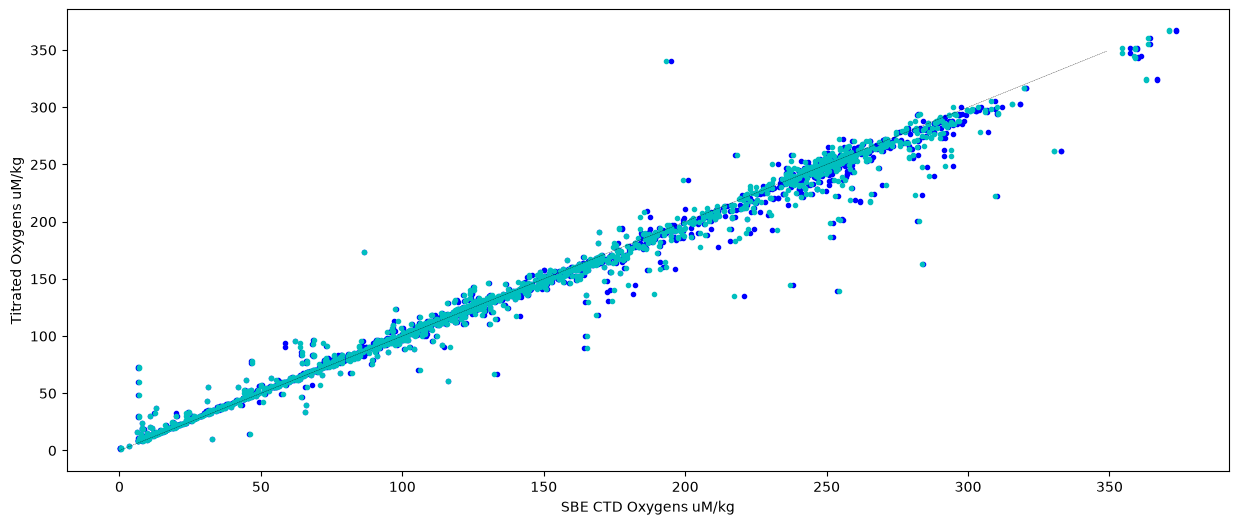

In [36]:
fig, ax = plt.subplots(figsize=(15, 6))
plt.plot(df_merged['sbox0mm/kg']*ratio_cor1,df_merged['O2, uM/kg00'],'b.')
plt.plot(df_merged['sbox1mm/kg']*ratio_cor2,df_merged['O2, uM/kg11'],'c.')
plt.plot(range(0,350,1),range(0,350,1),'k--',linewidth=0.25)
plt.ylabel('Titrated Oxygens uM/kg')
plt.xlabel('SBE CTD Oxygens uM/kg')

In [37]:
## Load Hand QC'D Oxy File and replot above

In [48]:
qcd_oxy_file = '/Users/bell/Downloads/WCOA26_O2_compiled.merged_edited.edited.csv'

In [49]:
qc_df = pd.read_csv(qcd_oxy_file, parse_dates=True, index_col='datetime')
qc_df1 = qc_df[qc_df['QC_Flag_1']==0]
qc_df2 = qc_df[qc_df['QC_Flag_2']==0]

Text(0.5, 0, 'Temperature')

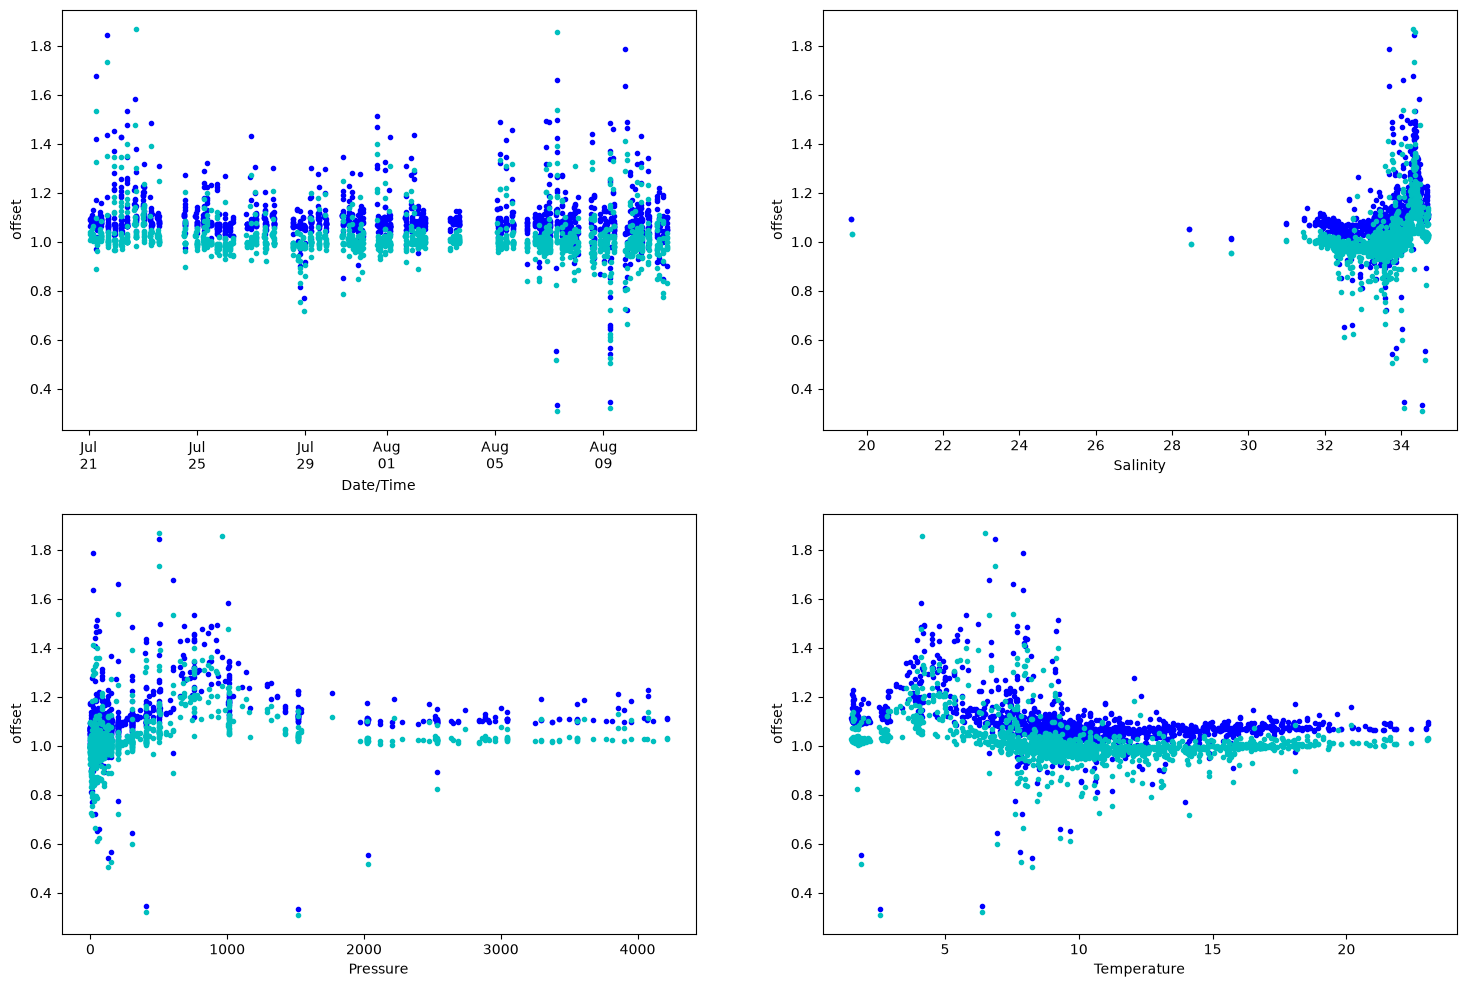

In [50]:
#Plot Basic Ration for Evaluation
fig, ax = plt.subplots(2,2,figsize=(18, 12))
plt.subplot(221)
plt.plot(qc_df1.index,qc_df1['O2, uM/kg00, ratio'],'b.')
plt.plot(qc_df2.index,qc_df2['O2, uM/kg11, ratio'],'c.')
ax = plt.gca()
xfmt = mdates.DateFormatter('%b\n%d')
ax.xaxis.set_major_formatter(xfmt)
plt.ylabel('offset')
plt.xlabel('Date/Time')

plt.subplot(222)
plt.plot(qc_df1['sal00'],qc_df1['O2, uM/kg00, ratio'],'b.')
plt.plot(qc_df2['sal11'],qc_df2['O2, uM/kg11, ratio'],'c.')
plt.ylabel('offset')
plt.xlabel('Salinity')

plt.subplot(223)
plt.plot(qc_df1['prdm'],qc_df1['O2, uM/kg00, ratio'],'b.')
plt.plot(qc_df2['prdm'],qc_df2['O2, uM/kg11, ratio'],'c.')
plt.ylabel('offset')
plt.xlabel('Pressure')

plt.subplot(224)
plt.plot(qc_df1['t090c'],qc_df1['O2, uM/kg00, ratio'],'b.')
plt.plot(qc_df2['t190c'],qc_df2['O2, uM/kg11, ratio'],'c.')
plt.ylabel('offset')
plt.xlabel('Temperature')


Text(0.5, 0, 'SBE CTD Oxygens uM/kg')

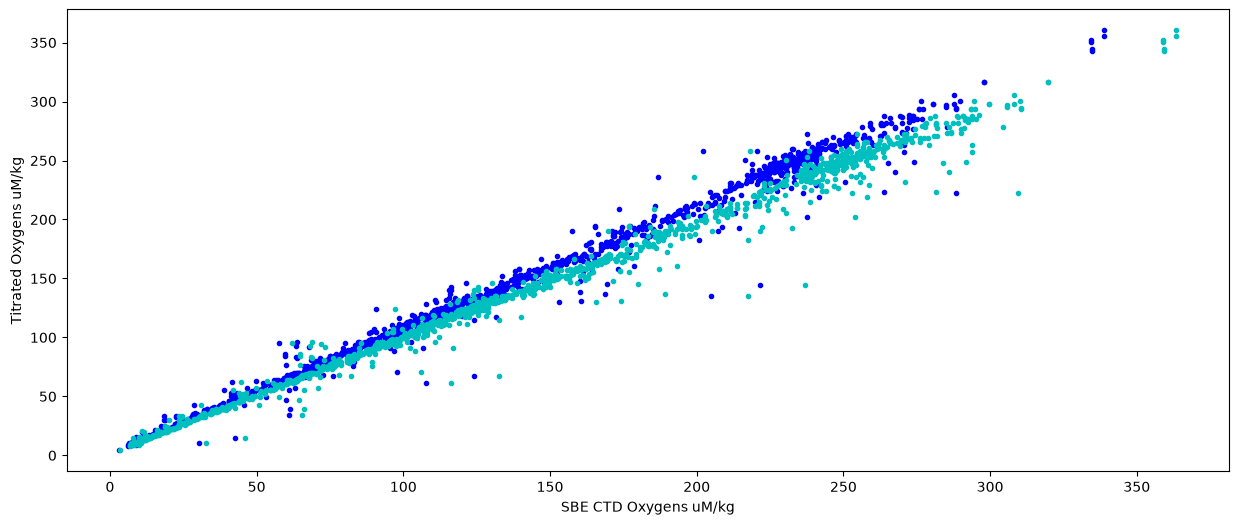

In [51]:
fig, ax = plt.subplots(figsize=(15, 6))
plt.plot(qc_df1['sbox0mm/kg'],qc_df1['O2, uM/kg00'],'b.')
plt.plot(qc_df2['sbox1mm/kg'],qc_df2['O2, uM/kg11'],'c.')
plt.ylabel('Titrated Oxygens uM/kg')
plt.xlabel('SBE CTD Oxygens uM/kg')

Text(0.5, 0, 'SBE CTD Oxygens uM/kg')

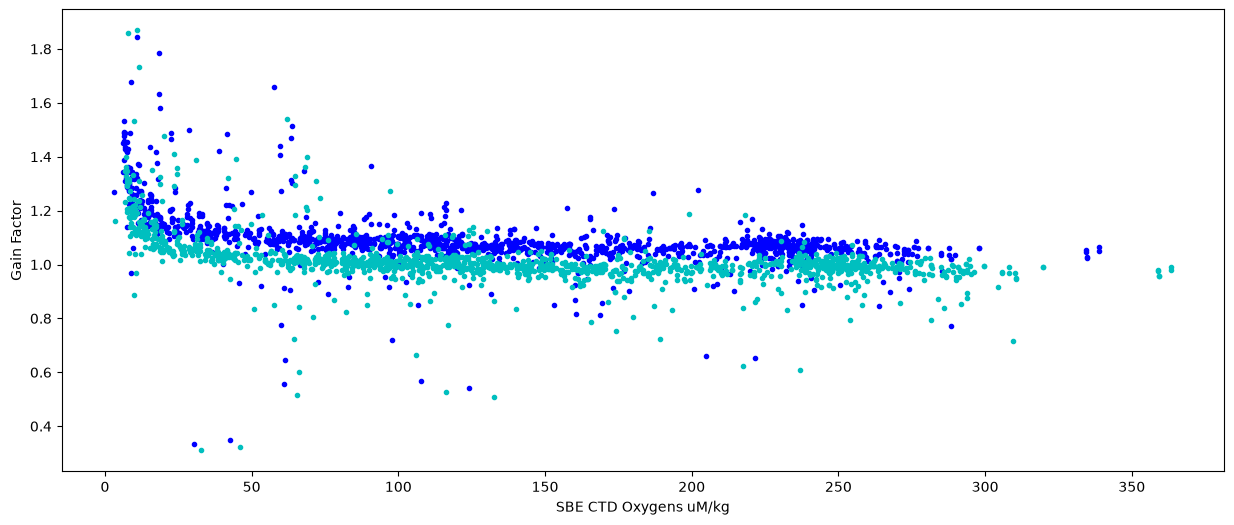

In [52]:
fig, ax = plt.subplots(figsize=(15, 6))
plt.plot(qc_df1['sbox0mm/kg'],qc_df1['O2, uM/kg00, ratio'],'b.')
plt.plot(qc_df2['sbox1mm/kg'],qc_df2['O2, uM/kg11, ratio'],'c.')
plt.ylabel('Gain Factor')
plt.xlabel('SBE CTD Oxygens uM/kg')

Text(0.5, 0, 'Date/Time')

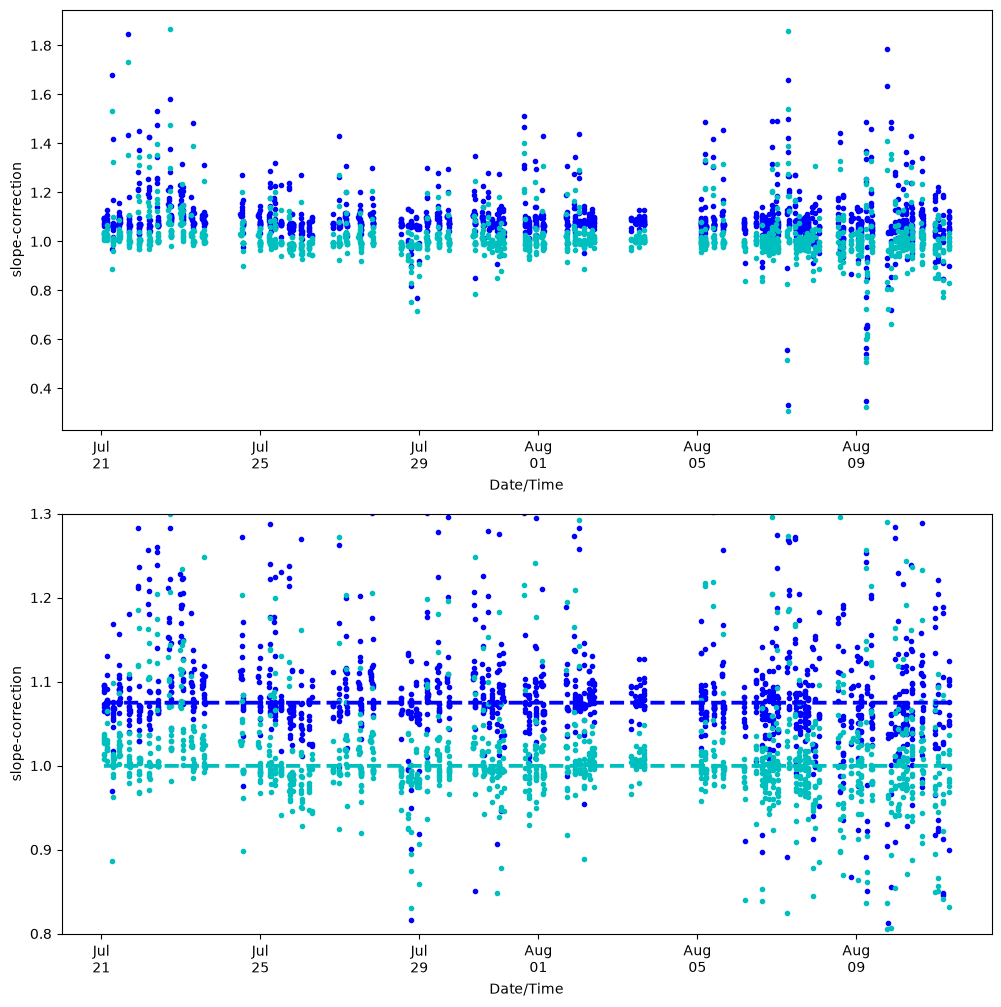

In [54]:
#Plot Basic Ratio for Evaluation
fig, ax = plt.subplots(2,1,figsize=(12, 12))
plt.subplot(211)
plt.plot(qc_df1.index,(qc_df1['O2, uM/kg00']/qc_df1['sbox0mm/kg']),'b.')
plt.plot(qc_df2.index,(qc_df2['O2, uM/kg11']/qc_df2['sbox1mm/kg']),'c.')
ax = plt.gca()
xfmt = mdates.DateFormatter('%b\n%d')
ax.xaxis.set_major_formatter(xfmt)
plt.ylabel('slope-correction')
plt.xlabel('Date/Time')

plt.subplot(212)
plt.plot(qc_df1.index,(qc_df1['O2, uM/kg00']/qc_df1['sbox0mm/kg']),'b.')
plt.plot(qc_df2.index,(qc_df2['O2, uM/kg11']/qc_df2['sbox1mm/kg']),'c.')
plt.plot(qc_df1.index,np.ones(len(qc_df1))*(qc_df1['O2, uM/kg00']/qc_df1['sbox0mm/kg']).median(),'b--',linewidth=2.75)
plt.plot(qc_df2.index,np.ones(len(qc_df2))*(qc_df2['O2, uM/kg11']/qc_df2['sbox1mm/kg']).median(),'c--',linewidth=2.75)
ax = plt.gca()
ax.set_ylim([.8,1.3])
xfmt = mdates.DateFormatter('%b\n%d')
ax.xaxis.set_major_formatter(xfmt)
plt.ylabel('slope-correction')
plt.xlabel('Date/Time')


In [55]:
print('Primary Corr Ratio:   median:{0:.3f} mean:{1:.3f} '.format((df_merged['O2, uM/kg00']/df_merged['sbox0mm/kg']).median(), (df_merged['O2, uM/kg00']/df_merged['sbox0mm/kg']).mean()))
print('Secondary Corr Ratio: median:{0:.3f} mean:{1:.3f} '.format((df_merged['O2, uM/kg11']/df_merged['sbox1mm/kg']).median(), (df_merged['O2, uM/kg11']/df_merged['sbox1mm/kg']).mean()))

Primary Corr Ratio:   median:1.076 mean:1.135 
Secondary Corr Ratio: median:1.000 mean:1.034 


In [56]:
print('Primary Corr Ratio:   median:{0:.3f} mean:{1:.3f} '.format((qc_df1['O2, uM/kg00']/qc_df1['sbox0mm/kg']).median(), (qc_df1['O2, uM/kg00']/qc_df1['sbox0mm/kg']).mean()))
print('Secondary Corr Ratio: median:{0:.3f} mean:{1:.3f} '.format((qc_df2['O2, uM/kg11']/qc_df2['sbox1mm/kg']).median(), (qc_df2['O2, uM/kg11']/qc_df2['sbox1mm/kg']).mean()))

Primary Corr Ratio:   median:1.075 mean:1.092 
Secondary Corr Ratio: median:1.000 mean:1.015 


Text(0.5, 0, 'SBE CTD Oxygens uM/kg')

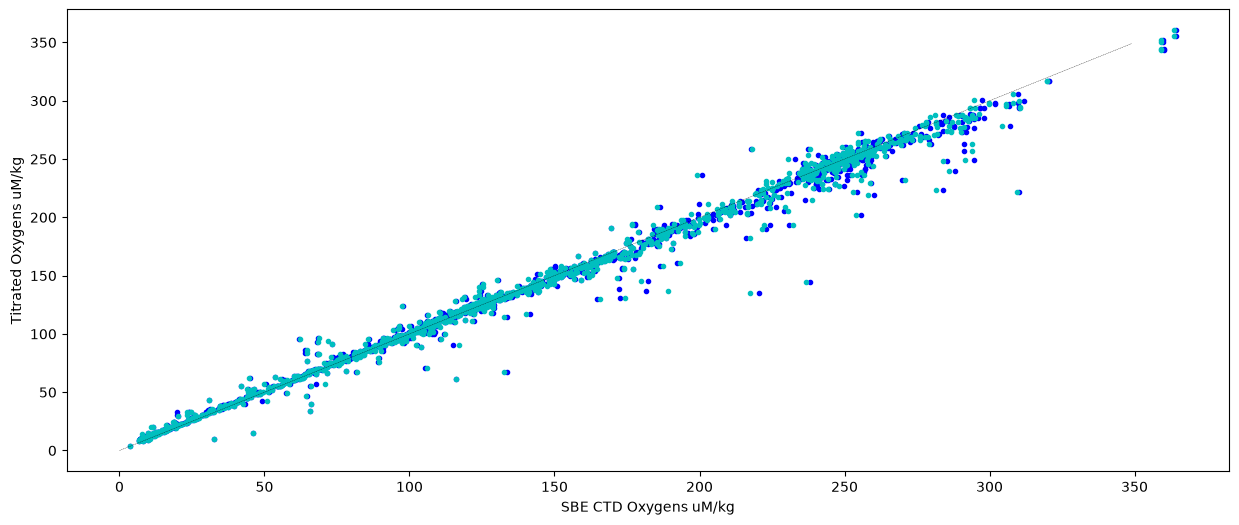

In [58]:
fig, ax = plt.subplots(figsize=(15, 6))
plt.plot(qc_df1['sbox0mm/kg']*ratio_cor1,qc_df1['O2, uM/kg00'],'b.')
plt.plot(qc_df2['sbox1mm/kg']*ratio_cor2,qc_df2['O2, uM/kg11'],'c.')
plt.plot(range(0,350,1),range(0,350,1),'k--',linewidth=0.25)
plt.ylabel('Titrated Oxygens uM/kg')
plt.xlabel('SBE CTD Oxygens uM/kg')